# Systems check

Laya and Jev side by side.

This notebook:

1. checks that Laya runs locally on the GPU, and how fast it answers,
2. pins the concrete Jev version behind `jev-latest`,
3. puts the same product and questions to both systems and compares the answers,
4. gives a first estimate of what a full run takes.

Before running: start Laya with `just laya` in a terminal, and put the Jev key in `.env` as `JEV_API_KEY`.
Jev calls are billed at $0.042 per million input tokens; running the whole notebook costs about a cent.

In [1]:
import json
import os
import sys
import time
from pathlib import Path
from statistics import median

import duckdb
import httpx
import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from IPython.display import Markdown, display

# The notebooks live in notebooks/; every path below is from the project root
os.chdir(next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists()))

assert Path(sys.prefix).resolve() == Path(".venv").resolve(), (
    f"The kernel runs {sys.executable}, not this project's .venv. Start Jupyter with `just lab`."
)
load_dotenv()

LAYA_URL = "http://127.0.0.1:8765"
LAYA_MODEL = "english"
LAYA_VERSION = "0.4.18"  # the version `just laya` runs
JEV_URL = "https://api.typesafe.ai"
JEV_ALIAS = "jev-latest"
JEV_PINNED = "jev-1.14.0"  # what jev-latest resolved to on 31 October 2026
JEV_API_KEY = os.environ.get("JEV_API_KEY")
assert JEV_API_KEY, "Put the Jev key in .env as JEV_API_KEY"

SAMPLE = "data/sample.parquet"
REQUEST = json.loads(Path("request.json").read_text())
QUESTIONS = REQUEST["questions"]

### The client

One class for both systems: only the base URL, the model and the API key differ.
`decide` sends one state, `decide_batch` sends up to 64 states in one call (Laya only, with optional `sort_by_length` and `batch_size`).
Both return the parsed response and the round-trip time in milliseconds.

In [2]:
class SystemOne:
    def __init__(self, name: str, base_url: str, model: str, api_key: str | None = None):
        self.name = name
        self.model = model
        headers = {"Authorization": f"Bearer {api_key}"} if api_key else {}
        self.http = httpx.Client(base_url=base_url, headers=headers, timeout=120)

    def post(self, path: str, body: dict) -> tuple[httpx.Response, float]:
        start = time.perf_counter()
        response = self.http.post(path, json={"model": self.model, **body})
        return response, (time.perf_counter() - start) * 1000

    def decide(self, state: str, questions: dict) -> tuple[dict, float]:
        response, ms = self.post("/v1/systemone", {"state": state, "questions": questions})
        response.raise_for_status()
        return response.json(), ms

    def decide_batch(self, states: list[str], questions: dict, **options) -> tuple[list[dict], float]:
        response, ms = self.post("/v1/systemone/batch", {"states": states, "questions": questions, **options})
        response.raise_for_status()
        return response.json()["results"], ms


laya = SystemOne("Laya", LAYA_URL, LAYA_MODEL)
jev = SystemOne("Jev", JEV_URL, JEV_ALIAS, JEV_API_KEY)

### Helpers

Reading an answer, the ground truth of a sample product, and the display and chart helpers.

In [3]:
# Option labels of `food_group`, keyed by the Open Food Facts tag they stand for
FOOD_GROUP_OPTION = {
    "en:alcoholic-beverages": "alcoholic beverages",
    "en:beverages": "beverages",
    "en:cereals-and-potatoes": "cereals and potatoes",
    "en:composite-foods": "composite foods",
    "en:fats-and-sauces": "fats and sauces",
    "en:fish-meat-eggs": "fish, meat and eggs",
    "en:fruits-and-vegetables": "fruits and vegetables",
    "en:milk-and-dairy-products": "milk and dairy products",
    "en:salty-snacks": "salty snacks",
    "en:sugary-snacks": "sugary snacks",
}
assert list(FOOD_GROUP_OPTION.values()) == list(QUESTIONS["food_group"]["criteria"])

GRADES = "ABCDE"  # the Nutri-Score levels, index 0 first
OPTIONS = {
    "food_group": list(QUESTIONS["food_group"]["criteria"]),
    "ultra_processed": ["yes", "no"],
    "nutriscore": list(GRADES),
}


def probabilities(response: dict, question: str) -> list[float]:
    """The probability of every option of `question`, in the order of OPTIONS."""
    answer = response["answers"][question]
    if answer["type"] == "noul":
        return [answer["noul"], 1 - answer["noul"]]
    if answer["type"] == "score":
        return [answer["probabilities"][str(level)] for level in range(len(GRADES))]
    return [answer["probabilities"][option] for option in OPTIONS[question]]


def read_answer(response: dict, question: str) -> tuple[str, float]:
    """The answer to `question` and its probability: the most likely option."""
    probs = probabilities(response, question)
    best = max(range(len(probs)), key=probs.__getitem__)
    return OPTIONS[question][best], probs[best]


def truth_of(product) -> dict:
    return {
        "food_group": FOOD_GROUP_OPTION[product.food_group],
        "ultra_processed": "yes" if product.ultra_processed else "no",
        "nutriscore": product.nutriscore,
    }


def answers_table(responses: dict[str, dict], truth: dict | None = None) -> pd.DataFrame:
    rows = []
    for question in QUESTIONS:
        row = {"question": question}
        if truth:
            row["truth"] = truth[question]
        for system, response in responses.items():
            answer, probability = read_answer(response, question)
            mark = "" if truth is None else ("  ✓" if answer == truth[question] else "  ✗")
            row[system] = answer + mark
            row[f"{system} p"] = probability
        rows.append(row)
    return pd.DataFrame(rows)


def show(df: pd.DataFrame, precision: int = 2) -> None:
    display(df.style.hide(axis="index").format(thousands=",", precision=precision))


def md_escape(text: str) -> str:
    for char in "\\`*_[]<>#|":
        text = text.replace(char, "\\" + char)
    return text


def show_state(state: str, heading: str) -> None:
    lines = "\n".join(f"> {md_escape(line)}  " for line in state.splitlines())
    display(Markdown(f"#### {md_escape(heading)}\n\n{lines}"))

In [4]:
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID, AXIS = "#fcfcfb", "#e1e0d9", "#c3c2b7"
COLOR = {"Laya": "#2a78d6", "Jev": "#eb6834"}

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "figure.dpi": 120,
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 10.5,
    "text.color": INK,
    "axes.labelcolor": INK_2,
    "axes.edgecolor": AXIS,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlelocation": "left",
    "axes.titlesize": 11,
    "axes.titlepad": 10,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": AXIS,
    "ytick.color": AXIS,
    "xtick.labelcolor": MUTED,
    "ytick.labelcolor": INK_2,
})


def plot_answers(responses: dict[str, dict], title: str, truth: dict | None = None) -> None:
    """Every option's probability, per question and per system."""
    fig, axes = plt.subplot_mosaic(
        [["food_group", "ultra_processed"], ["food_group", "nutriscore"]],
        figsize=(10, 4.8), layout="constrained", width_ratios=[3, 2], height_ratios=[1, 2.2],
    )
    for question, ax in axes.items():
        options = OPTIONS[question]
        rows = range(len(options))
        for offset, (system, response) in zip((-0.2, 0.2), responses.items()):
            ax.barh([row + offset for row in rows], probabilities(response, question),
                    height=0.38, color=COLOR[system], label=system)
        labels = [f"{option}  (truth)" if truth and option == truth[question] else option for option in options]
        ax.set_yticks(rows, labels)
        for label, option in zip(ax.get_yticklabels(), options):
            if truth and option == truth[question]:
                label.set_fontweight("bold")
                label.set_color(INK)
        ax.invert_yaxis()
        ax.set_xlim(0, 1)
        ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
        ax.tick_params(axis="y", length=0)
        ax.grid(axis="y", visible=False)
        ax.set_title(question, fontfamily="monospace")
    handles, names = axes["food_group"].get_legend_handles_labels()
    fig.legend(handles, names, loc="outside upper right", ncols=2, frameon=False)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold", fontsize=12)
    plt.show()

## 1. Laya: is it up, and on which device?

`/health` reports where each checkpoint actually computes.
`mps` is the Apple GPU; a checkpoint that falls back to the CPU still answers correctly, only about ten times slower, so the fallback count matters.

In [5]:
try:
    health = laya.http.get("/health").json()
except httpx.ConnectError:
    raise RuntimeError("Laya is not running: start it with `just laya` in a terminal") from None

LAYA_REVISION = health["revisions"][LAYA_MODEL]
LAYA_MODEL_VERSION = f"laya {LAYA_VERSION}, {LAYA_MODEL}@{LAYA_REVISION[:7]}"

show(pd.DataFrame([{
    "status": health["status"],
    "device": health["checkpoint_devices"][LAYA_MODEL],
    "CPU fallbacks": health["cpu_fallbacks"][LAYA_MODEL]["count"],
    "checkpoint revision": LAYA_REVISION[:7],
    "model_version to record": LAYA_MODEL_VERSION,
}]))

status,device,CPU fallbacks,checkpoint revision,model_version to record
ok,mps,0,7b928d8,"laya 0.4.18, english@7b928d8"


### Warm-up and speed

On a freshly started server the first call compiles the GPU kernels and can take several seconds.
If the server has already answered something, every call is warm.

In [6]:
calls = [laya.decide(REQUEST["state"], QUESTIONS)[1] for _ in range(10)]

print(f"first call {calls[0]:,.0f} ms, then a median of {median(calls[1:]):,.0f} ms for three questions")

first call 383 ms, then a median of 195 ms for three questions


## 2. Jev: which version is behind `jev-latest`?

Aliases move when TypeSafe ships a release, so the experiment pins the concrete version.
`/v1/models` lists the aliases; only an answer tells which version an alias points to today.

In [7]:
show(pd.DataFrame(jev.http.get("/v1/models").raise_for_status().json()["models"]))

jev.model = JEV_PINNED  # every call from here on goes to the pinned version

name,description,release_date
jev-latest,The latest iteration of TypeSafe's System One Model: Jev,2026-10-22T02:00:00+00:00
jev-preview,Preview the next version of Jev before it gets promoted to jev-latest. Most of the time this is the same as jev-latest,2026-10-14T20:14:00+00:00


## 3. One product, both systems

Pick any product from the sample.
Keep to ids 1 to 10,000, the calibration split, so the evaluation split stays unseen until the runs.

#### \#1 Gourmet Swiss Style Yogurt (calibration)

> Product: Gourmet Swiss Style Yogurt  
> Ingredients: Cultured pasteurized grade a fat free milk, milk, solids, live & active cultures: bifidus, bulgaricus & thermophilus, cane sugar, mango puree, tapioca starch, pectin, vitamins & minerals added. (no preservatives).  
> Nutrition per 100 g: energy 76 kcal, fat 0 g, saturated fat 0 g, sugars 13.53 g, salt 0.14 g, fibre 0 g, proteins 3.53 g  

question,truth,Laya,Laya p,Jev,Jev p
food_group,milk and dairy products,milk and dairy products ✓,0.96,milk and dairy products ✓,1.00
ultra_processed,yes,yes ✓,0.85,yes ✓,0.73
nutriscore,B,B ✓,0.45,C ✗,0.60


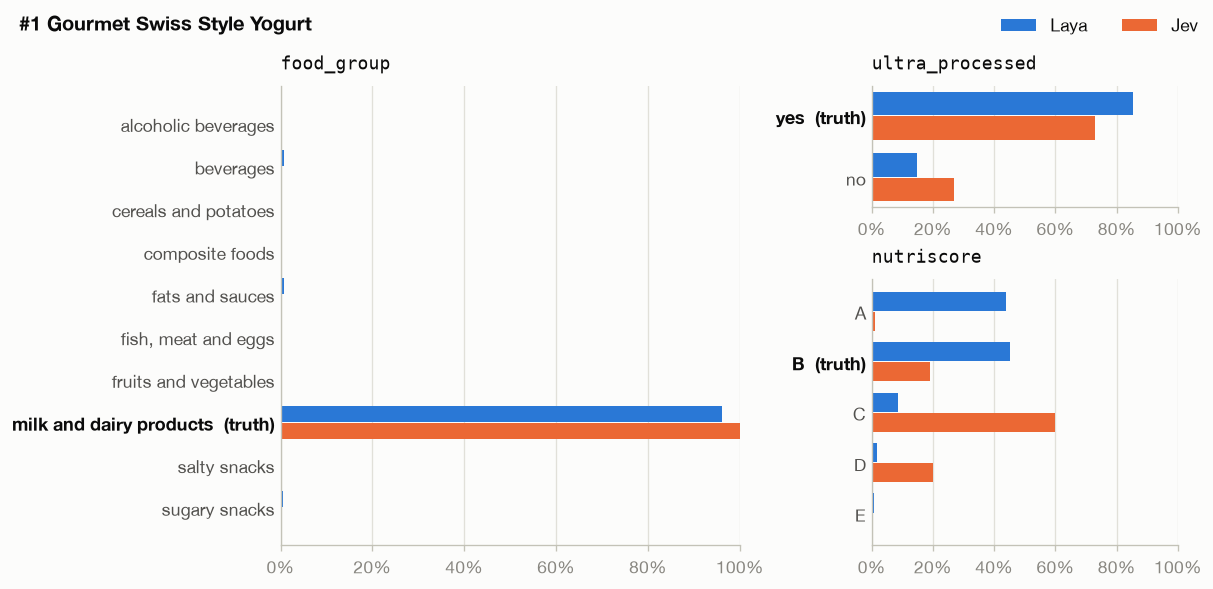

In [8]:
PRODUCT_ID = 1

product = duckdb.sql(f"SELECT * FROM '{SAMPLE}' WHERE id = {PRODUCT_ID}").df().iloc[0]
truth = truth_of(product)
show_state(product.state, f"#{PRODUCT_ID} {product['name']} ({product.split})")

responses = {
    "Laya": laya.decide(product.state, QUESTIONS)[0],
    "Jev": jev.decide(product.state, QUESTIONS)[0],
}
show(answers_table(responses, truth))
plot_answers(responses, f"#{PRODUCT_ID} {product['name']}", truth)

The raw responses, exactly as they came back:

In [9]:
for system, response in responses.items():
    print(f"--- {system}")
    print(json.dumps(response, indent=2))

--- Laya
{
  "model": "laya-rl-agent",
  "answers": {
    "food_group": {
      "type": "choice",
      "choice": "milk and dairy products",
      "confidence": 0.8945,
      "probabilities": {
        "alcoholic beverages": 0.0033,
        "beverages": 0.0079,
        "cereals and potatoes": 0.0037,
        "composite foods": 0.0035,
        "fats and sauces": 0.0083,
        "fish, meat and eggs": 0.0009,
        "fruits and vegetables": 0.0039,
        "milk and dairy products": 0.9614,
        "salty snacks": 0.0027,
        "sugary snacks": 0.0045
      }
    },
    "ultra_processed": {
      "type": "noul",
      "noul": 0.8538
    },
    "nutriscore": {
      "type": "score",
      "score": 0.7001,
      "confidence": 0.3584,
      "probabilities": {
        "0": 0.4389,
        "1": 0.4517,
        "2": 0.0864,
        "3": 0.0165,
        "4": 0.0065
      },
      "legend": {
        "0": "A: best nutritional quality",
        "1": "B: good nutritional quality",
        "2": 

### The shape of the responses

Every field path in both responses, with option labels and level numbers folded into `*` because they are data, not structure.

In [10]:
def field_paths(value, path: str = "") -> set[str]:
    if not isinstance(value, dict):
        return {path}
    data_keys = path.endswith(("probabilities", "legend"))
    return set().union(*(field_paths(child, f"{path}.{'*' if data_keys else key}".lstrip("."))
                         for key, child in value.items()))


paths = {system: field_paths(response) for system, response in responses.items()}
show(pd.DataFrame(
    [{"field": path, **{system: "✓" if path in found else "" for system, found in paths.items()}}
     for path in sorted(set().union(*paths.values()))]
))

field,Laya,Jev
answers.food_group.choice,✓,✓
answers.food_group.confidence,✓,✓
answers.food_group.probabilities.*,✓,✓
answers.food_group.type,✓,✓
answers.nutriscore.confidence,✓,✓
answers.nutriscore.legend.*,✓,✓
answers.nutriscore.probabilities.*,✓,✓
answers.nutriscore.score,✓,✓
answers.nutriscore.type,✓,✓
answers.ultra_processed.noul,✓,✓


### What the harness has to handle

**The model name.**
Jev names its concrete version; Laya always says `laya-rl-agent`, so its `model_version` comes from `/health`.

In [11]:
show(pd.DataFrame([
    {"system": "Laya", "model field": responses["Laya"]["model"], "model_version to record": LAYA_MODEL_VERSION},
    {"system": "Jev", "model field": responses["Jev"]["model"], "model_version to record": JEV_PINNED},
]))

system,model field,model_version to record
Laya,laya-rl-agent,"laya 0.4.18, english@7b928d8"
Jev,jev-1.14.0,jev-1.14.0


**Options as a list.**
Laya accepts `choice` options as a plain list; Jev answers 422 and wants a dictionary of descriptions, which is why `request.json` uses one.

In [12]:
as_list = {"food_group": {**QUESTIONS["food_group"], "criteria": list(QUESTIONS["food_group"]["criteria"])}}
for system in (laya, jev):
    response, _ = system.post("/v1/systemone", {"state": REQUEST["state"], "questions": as_list})
    detail = response.json().get("detail")
    print(f"{system.name}: HTTP {response.status_code}", f"- {detail[0]['msg']}" if detail else "")

Laya: HTTP 200 
Jev: HTTP 422 - Input should be a valid dictionary


**Precision.**
Jev rounds every probability to 2 decimals, Laya to 4.
Jev's confidence therefore moves in steps of 1%, and many confident rows tie at exactly 100%, which makes its reliability and coverage curves coarse.

In [13]:
def decimals(value: float) -> int:
    return len(f"{value:.10f}".rstrip("0").split(".")[1])


show(pd.DataFrame([
    {
        "system": system,
        "most decimals in a probability": max(decimals(p) for q in QUESTIONS for p in probabilities(response, q)),
        "food_group probabilities at exactly 0 or 1": sum(p in (0, 1) for p in probabilities(response, "food_group")),
    }
    for system, response in responses.items()
]))

system,most decimals in a probability,food_group probabilities at exactly 0 or 1
Laya,4,0
Jev,2,10


**Tokens.**
Each system counts input tokens with its own tokenizer, so the two counts measure different things.
Jev bills its count; Laya's only shows how much of the 512-token window the request used.

In [14]:
show(pd.DataFrame([{"system": system, **response["usage"]} for system, response in responses.items()]))

system,input_tokens,output_tokens
Laya,671,0
Jev,866,156


**Truncation.**
Laya reads at most 512 tokens and can report whether a state was cut (`truncated`, `state_tokens`, `state_tokens_dropped`).
`just laya` runs with `LAYA_JEV_STRICT=1`, which strips those fields so the response looks exactly like Jev's.
The runs need them, so the harness has to run Laya without strict mode.

In [15]:
print("Laya usage fields in strict mode:", sorted(responses["Laya"]["usage"]))

Laya usage fields in strict mode: ['input_tokens', 'output_tokens']


**Batch against single calls.**
A batch pads every state to the longest one in it, so a product's probabilities depend slightly on its neighbours.
Alone in a batch it matches a single call exactly; next to 15 other products it moves in the third or fourth decimal.
Every Laya row in the runs therefore goes through the same batch route with the same settings, never a mix.

In [16]:
neighbours = duckdb.sql(
    f"SELECT state FROM '{SAMPLE}' WHERE split = 'calibration' AND id <> {PRODUCT_ID} ORDER BY id LIMIT 15"
).df().state.tolist()
(alone,), _ = laya.decide_batch([product.state], QUESTIONS)
(with_neighbours, *_), _ = laya.decide_batch([product.state, *neighbours], QUESTIONS)

show(pd.DataFrame([
    {
        "question": question,
        **{
            f"largest difference to a single call, {label}": max(
                abs(a - b) for a, b in zip(probabilities(responses["Laya"], question), probabilities(batched, question))
            )
            for label, batched in (("alone in a batch", alone), ("with 15 neighbours", with_neighbours))
        },
    }
    for question in QUESTIONS
]), precision=4)

question,"largest difference to a single call, alone in a batch","largest difference to a single call, with 15 neighbours"
food_group,0.0000,0.0002
ultra_processed,0.0000,0.0007
nutriscore,0.0000,0.0013


### Own state

Write any product the way the sample writes them, and see what both systems make of it.

#### My state

> Product: Butter croissant  
> Ingredients: wheat flour, butter (milk) 25%, water, sugar, yeast, eggs, salt, wheat gluten, emulsifier: mono- and diglycerides of fatty acids.  
> Nutrition per 100 g: energy 420 kcal, fat 23 g, saturated fat 15 g, sugars 8 g, salt 1.1 g, fibre 2 g, proteins 8 g  

question,Laya,Laya p,Jev,Jev p
food_group,fats and sauces,0.23,sugary snacks,0.86
ultra_processed,no,0.61,yes,0.75
nutriscore,B,0.53,D,0.62


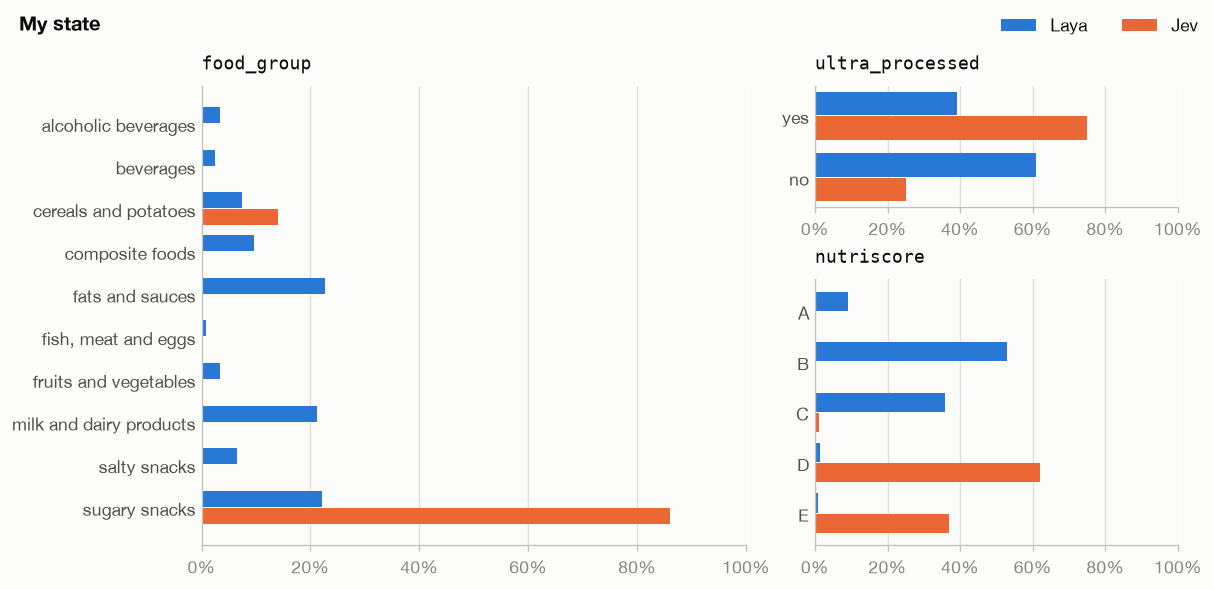

In [17]:
MY_STATE = """Product: Butter croissant
Ingredients: wheat flour, butter (milk) 25%, water, sugar, yeast, eggs, salt, wheat gluten, emulsifier: mono- and diglycerides of fatty acids.
Nutrition per 100 g: energy 420 kcal, fat 23 g, saturated fat 15 g, sugars 8 g, salt 1.1 g, fibre 2 g, proteins 8 g"""

show_state(MY_STATE, "My state")
mine = {"Laya": laya.decide(MY_STATE, QUESTIONS)[0], "Jev": jev.decide(MY_STATE, QUESTIONS)[0]}
show(answers_table(mine))
plot_answers(mine, "My state")

## An estimated full run

Laya reads every state once per question, at up to 512 tokens, and is bound by GPU compute: batching helps little.
Measured on 31 October 2026 on the M3 Pro, in products per second:

| How Laya is called | Products per second |
| --- | --- |
| single calls, one after the other | 4.4 |
| batches of 64 | 3.5 |
| batches of 64, `sort_by_length`, forward passes of 16 | 4.9 |

Plain batches of 64 are the slowest, because every row is padded to the longest state in the batch.
The cell below uses the fastest setting, on three batches of calibration rows.
Jev gets a handful of single calls, enough for the tokens per product and the latency.
Step 5 measures the real numbers on all 100,000 rows.

In [18]:
BATCH = 64
LAYA_BATCH_OPTIONS = {"sort_by_length": True, "batch_size": 16}
FULL_RUN = 100_000
JEV_USD_PER_MILLION_TOKENS = 0.042
JEV_REQUESTS_PER_MINUTE = 1_000  # a pool kept well under the published 1,200

states = duckdb.sql(
    f"SELECT state FROM '{SAMPLE}' WHERE split = 'calibration' ORDER BY id LIMIT {3 * BATCH}"
).df().state.tolist()

laya_seconds = [laya.decide_batch(states[start:start + BATCH], QUESTIONS, **LAYA_BATCH_OPTIONS)[1] / 1000
                for start in range(0, len(states), BATCH)]
laya_per_second = BATCH / median(laya_seconds)

jev_calls = [jev.decide(state, QUESTIONS) for state in states[:8]]
jev_tokens = median(response["usage"]["input_tokens"] for response, _ in jev_calls)
jev_ms = median(ms for _, ms in jev_calls)

show(pd.DataFrame([
    {
        "system": "Laya",
        "measured": f"{laya_per_second:,.1f} products per second, batches of {BATCH}",
        "full run of 100,000": f"about {FULL_RUN / laya_per_second / 3600:,.1f} hours on this laptop",
        "cost": "own hardware",
    },
    {
        "system": "Jev",
        "measured": f"{jev_tokens:,.0f} input tokens and {jev_ms:,.0f} ms per product",
        "full run of 100,000": f"about {FULL_RUN / JEV_REQUESTS_PER_MINUTE:,.0f} minutes at {JEV_REQUESTS_PER_MINUTE:,} requests per minute",
        "cost": f"about ${FULL_RUN * jev_tokens / 1e6 * JEV_USD_PER_MILLION_TOKENS:,.2f}",
    },
]))

system,measured,"full run of 100,000",cost
Laya,"4.7 products per second, batches of 64",about 5.9 hours on this laptop,own hardware
Jev,858 input tokens and 159 ms per product,"about 100 minutes at 1,000 requests per minute",about $3.61
